# Phase 3 scratch: SQL velocity features + baseline model
Time split: train days 1 to 120, test days 121 to 182 (days 91 to 120 only pick the tree count). Budget: top 2% of test transactions.

In [1]:
import sys
sys.path.insert(0, '../../src')
import pandas as pd, features, model, viz
features.build_velocity()
df = model.load_frame()
train, test = model.split(df)
print(f'train {len(train):,} ({train.isFraud.mean():.2%} fraud), test {len(test):,} ({test.isFraud.mean():.2%} fraud)')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

train 414,542 (3.52% fraud), test 175,998 (3.44% fraud)


In [2]:
print(open('../../sql/03_velocity.sql').read())

-- Phase 3: velocity features. Every window looks backward only (past + current
-- transaction), so nothing here can see the future. No labels are used.
-- Rows without a uid (0.2%, missing D1) get NULL uid features.
CREATE OR REPLACE TABLE velocity AS
WITH t AS (
    SELECT
        b.TransactionID,
        b.TransactionDT AS ts,
        b.TransactionAmt AS amt,
        b.card1,
        i.uid,
        b.P_emaildomain,
        NULLIF(concat_ws('|', b.DeviceInfo, b.id_30, b.id_31, b.id_33), '') AS device_fp
    FROM base b
    JOIN identity i USING (TransactionID)
),
card AS (
    SELECT
        TransactionID,
        COUNT(*) OVER w1h  AS card1_txn_1h,
        COUNT(*) OVER w24h AS card1_txn_24h,
        COUNT(*) OVER w7d  AS card1_txn_7d,
        ts - LAG(ts) OVER (PARTITION BY card1 ORDER BY ts, TransactionID) AS card1_secs_since_prev
    FROM t
    WINDOW
        w1h  AS (PARTITION BY card1 ORDER BY ts RANGE BETWEEN 3600   PRECEDING AND CURRENT ROW),
        w24h AS (PARTITION BY car

In [3]:
res, models = model.run_baselines(df)
res

,transaction features only,+ velocity features
auc,0.9187,0.9207
flagged,3520.0000,3520.0000
fraud_total,6063.0000,6063.0000
fraud_caught,2539.0000,2512.0000
recall_at_budget,0.4188,0.4143
precision_at_budget,0.7213,0.7136
fraud_amt_total,950010.0000,950010.0000
fraud_amt_caught,330551.0000,324992.0000
n_features,433.0000,446.0000
trees,160.0000,141.0000


Is the small gap between the two variants real? Three seeds each (run by `seed_check.py`).

In [4]:
sc = pd.read_csv('../../data/processed/seed_check.csv')
sc.groupby('variant')[['auc', 'recall_at_budget', 'fraud_amt_caught']].agg(['mean', 'std']).round(4)

auc         recall_at_budget         fraud_amt_caught  \
                    mean     std             mean     std             mean   
variant                                                                      
+ velocity        0.9208  0.0016           0.4249  0.0038         340219.0   
transaction only  0.9216  0.0007           0.4224  0.0038         337351.0   

                              
                         std  
variant                       
+ velocity        10548.7142  
transaction only   4340.9790

In [5]:
m, cols, scores = models['+ velocity features']
model.save_predictions(test, scores, 'baseline')
imp = pd.read_csv('../../data/processed/shap_baseline.csv', index_col=0).iloc[:, 0]  # computed on the saved baseline model (~3 min)
imp.head(20)

TransactionAmt    0.175499
C13               0.152710
card6             0.115576
P_emaildomain     0.096807
C5                0.092115
V70               0.090137
D1                0.078677
C14               0.077673
card1             0.070621
D15               0.066636
card1_txn_7d      0.064694
D2                0.062988
card5             0.062925
C1                0.058738
R_emaildomain     0.058587
id_31             0.057324
C2                0.057088
card2             0.054751
C11               0.052266
D4                0.049885
Name: 0, dtype: float64

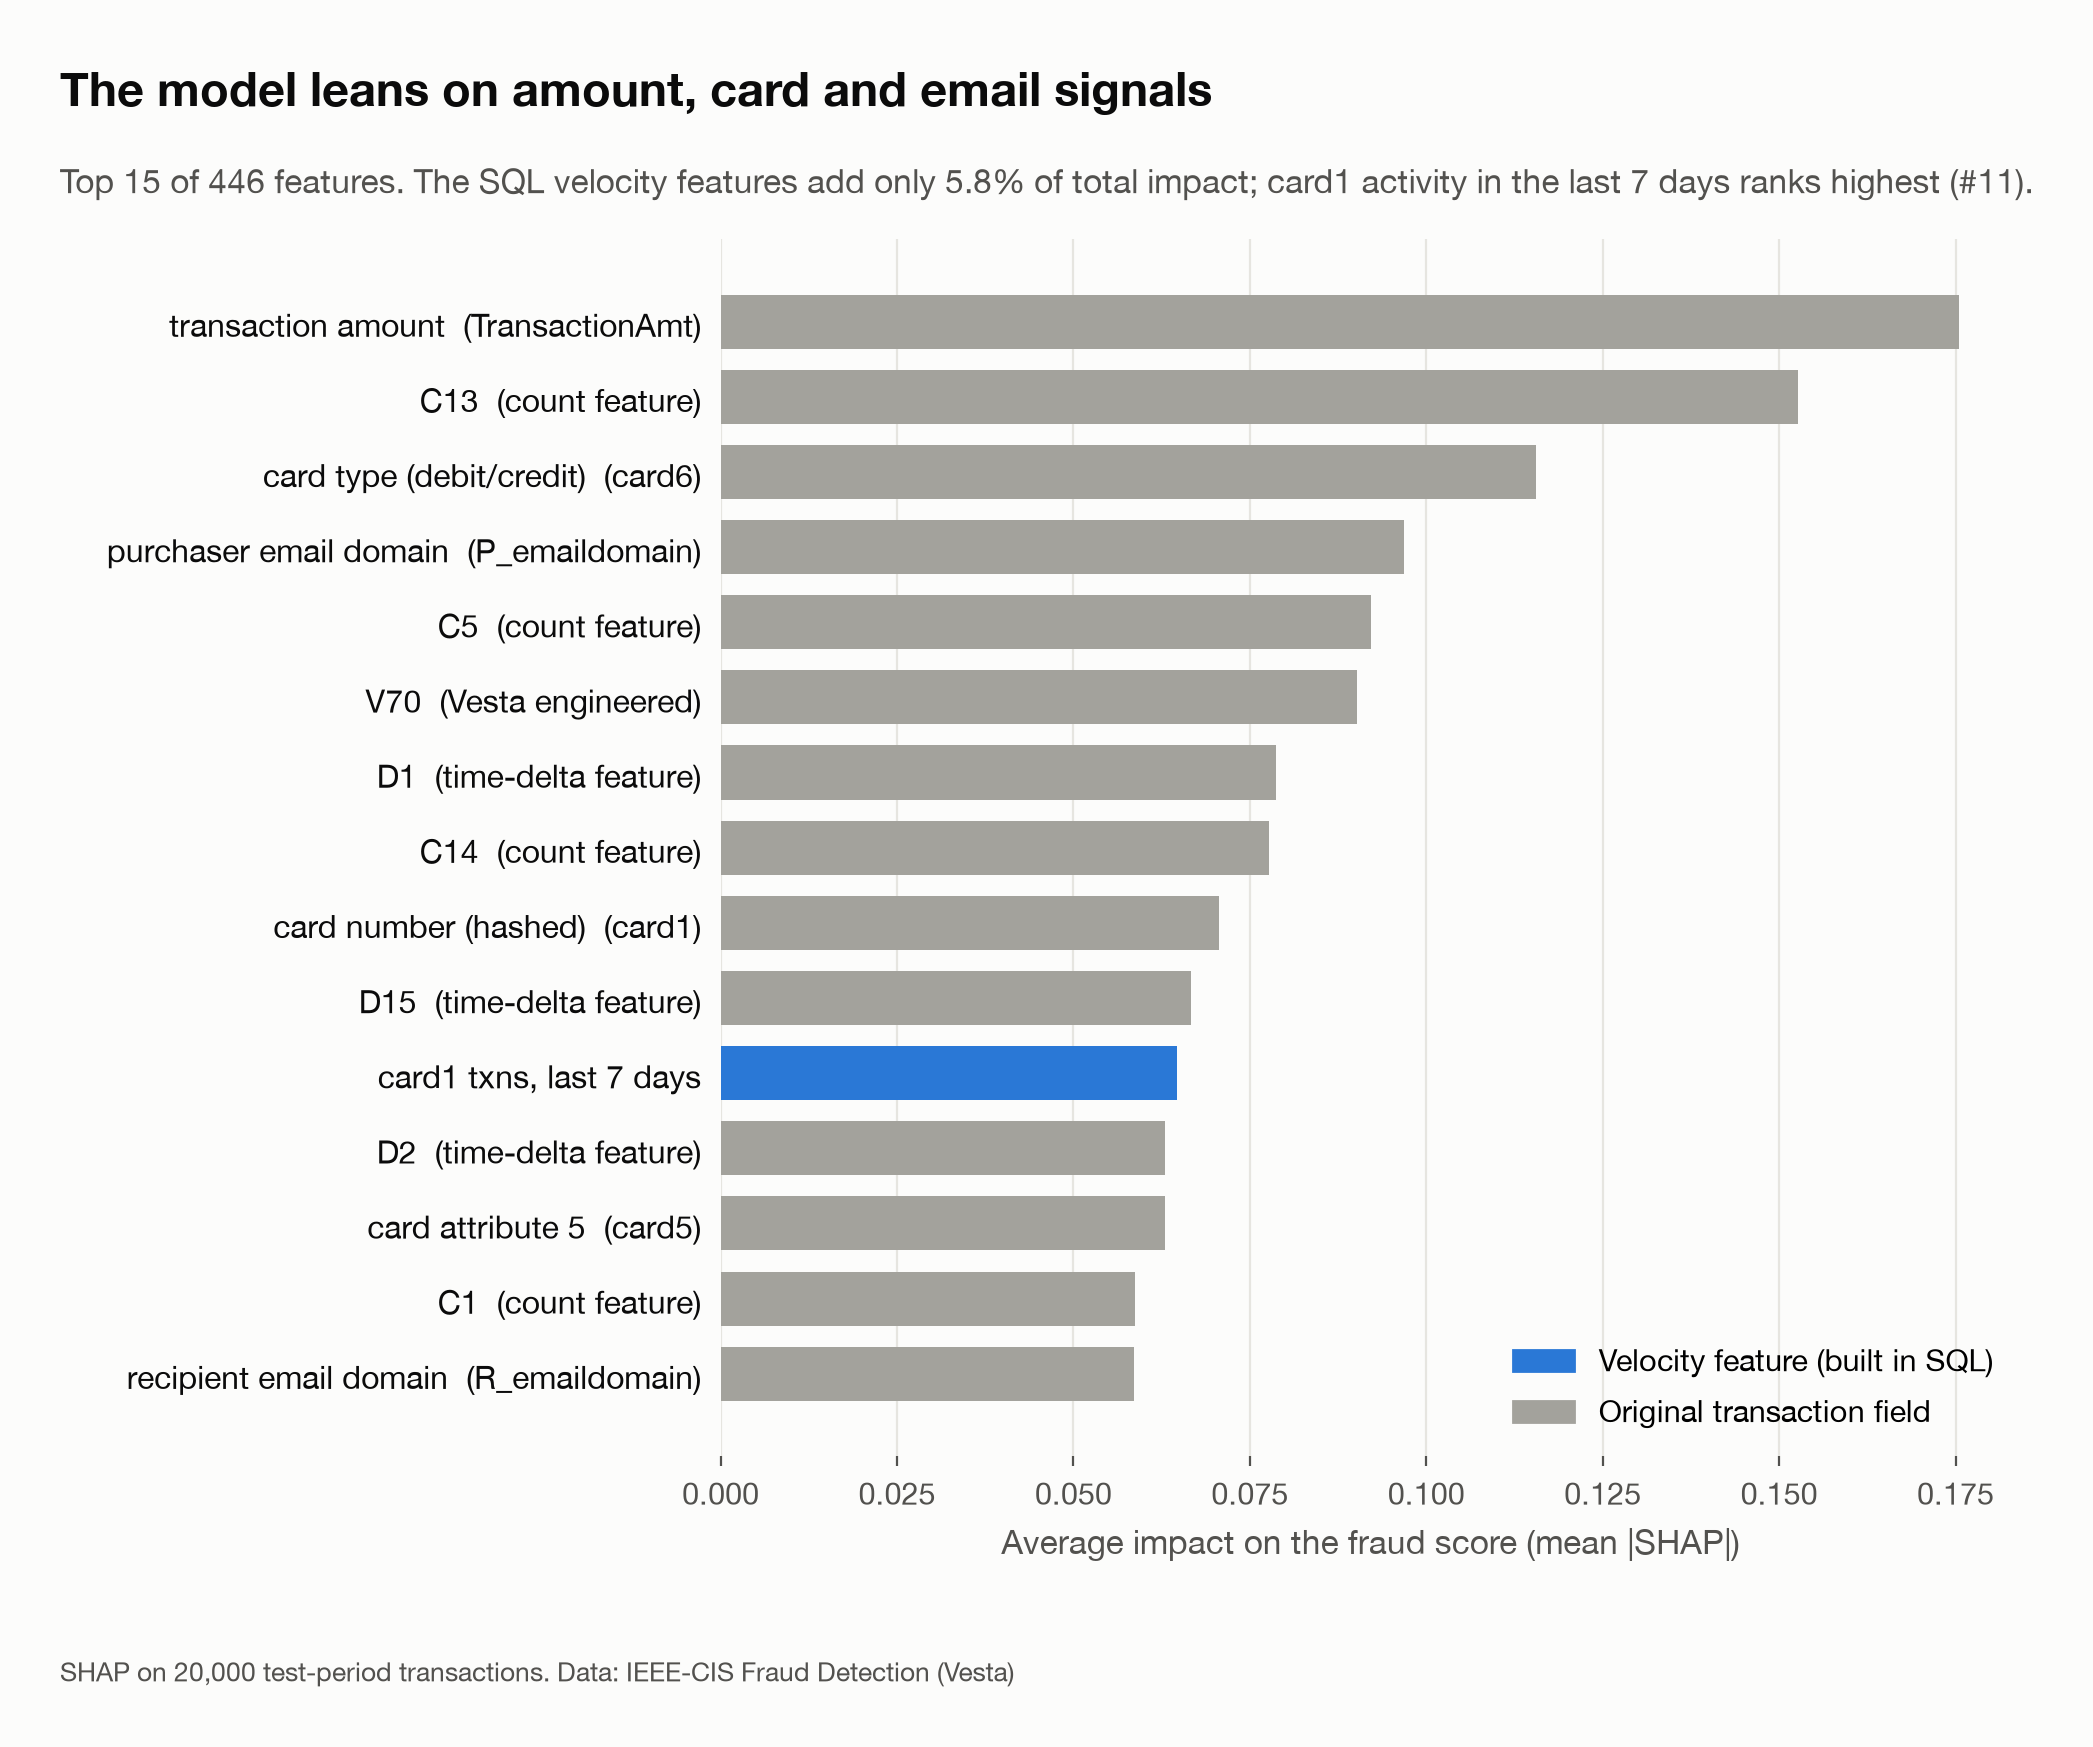

In [6]:
from IPython.display import Image
Image('../../figures/03_baseline_shap.png', width=700)